Ячейка 1: Импорты и настройки

In [1]:
import pandas as pd
import polars as pl
import time
import sys
import platform

# Имя файла, который мы оптимизировали на прошлом шаге
file_path = '../data/interim/full_data_optimized_full.parquet'

# Выведем конфигурацию для отчета
print(f"ОС: {platform.system()} {platform.release()}")
print(f"Python: {sys.version.split()[0]}")
print(f"Pandas: {pd.__version__}")
print(f"Polars: {pl.__version__}")

ОС: Windows 11
Python: 3.12.14
Pandas: 3.1.0
Polars: 2.0.0


Ячейка 2: Замеры Pandas (Обычный режим)

In [2]:
print("--- PANDAS ---")
pandas_times = {}

# 1. Чтение
t0 = time.perf_counter()
df_pd = pd.read_parquet(file_path)
pandas_times['Чтение Parquet'] = time.perf_counter() - t0

# 2. Фильтрация
t0 = time.perf_counter()
filtered_pd = df_pd[df_pd['altitude_1'] > 10000]
pandas_times['Фильтрация'] = time.perf_counter() - t0

# 3. Группировка и агрегирование (медиана по origin)
t0 = time.perf_counter()
grouped_pd = filtered_pd.groupby('origin', observed=True)['altitude_1'].median()
pandas_times['Группировка и агрегирование'] = time.perf_counter() - t0

# 4. Сортировка
t0 = time.perf_counter()
sorted_pd = grouped_pd.sort_values(ascending=False)
pandas_times['Сортировка'] = time.perf_counter() - t0

# 5. Соединение со справочником (создадим искусственный справочник аэропортов)
# Берем 100 самых частых origin, чтобы join был реалистичным
top_origins = df_pd['origin'].value_counts().head(100).index
ref_pd = pd.DataFrame({'origin': top_origins, 'city': [f"City_{i}" for i in range(100)]})

t0 = time.perf_counter()
merged_pd = df_pd.merge(ref_pd, on='origin', how='left')
pandas_times['Соединение таблиц'] = time.perf_counter() - t0

for op, t in pandas_times.items():
    print(f"{op}: {t:.4f} с")

--- PANDAS ---
Чтение Parquet: 1.9820 с
Фильтрация: 0.3944 с
Группировка и агрегирование: 0.0287 с
Сортировка: 0.0002 с
Соединение таблиц: 0.6610 с


Ячейка 3: Замеры Polars (Обычный режим - Eager)

In [3]:
print("--- POLARS (Eager) ---")
polars_times = {}

# 1. Чтение
t0 = time.perf_counter()
df_pl = pl.read_parquet(file_path)
polars_times['Чтение Parquet'] = time.perf_counter() - t0

# 2. Фильтрация
t0 = time.perf_counter()
filtered_pl = df_pl.filter(pl.col('altitude_1') > 10000)
polars_times['Фильтрация'] = time.perf_counter() - t0

# 3. Группировка и агрегирование
t0 = time.perf_counter()
grouped_pl = filtered_pl.group_by('origin').agg(pl.col('altitude_1').median())
polars_times['Группировка и агрегирование'] = time.perf_counter() - t0

# 4. Сортировка
t0 = time.perf_counter()
sorted_pl = grouped_pl.sort('altitude_1', descending=True)
polars_times['Сортировка'] = time.perf_counter() - t0

# 5. Соединение (справочник на Polars)
ref_pl = pl.DataFrame({'origin': top_origins, 'city': [f"City_{i}" for i in range(100)]})

t0 = time.perf_counter()
merged_pl = df_pl.join(ref_pl, on='origin', how='left')
polars_times['Соединение таблиц'] = time.perf_counter() - t0

for op, t in polars_times.items():
    print(f"{op}: {t:.4f} с")

--- POLARS (Eager) ---
Чтение Parquet: 1.7413 с
Фильтрация: 0.0984 с
Группировка и агрегирование: 0.0852 с
Сортировка: 0.0068 с
Соединение таблиц: 0.1846 с


Ячейка 4: Замеры Polars (Ленивый режим - Lazy)

In [4]:
print("--- POLARS (Lazy) ---")
polars_lazy_times = {}

# Замеряем "Цепочку операций" (Чтение + Фильтр + Группировка + Сортировка) целиком
t0 = time.perf_counter()

# Строим план
lazy_query = (
    pl.scan_parquet(file_path) # Ленивое чтение
    .filter(pl.col('altitude_1') > 10000)
    .group_by('origin')
    .agg(pl.col('altitude_1').median())
    .sort('altitude_1', descending=True)
)

# Выполняем план
result_lazy = lazy_query.collect()

polars_lazy_times['Цепочка операций (ленивый режим)'] = time.perf_counter() - t0
print(f"Цепочка операций (ленивый режим): {polars_lazy_times['Цепочка операций (ленивый режим)']:.4f} с")

--- POLARS (Lazy) ---
Цепочка операций (ленивый режим): 0.1142 с


Ячейка 5: Построение диаграммы

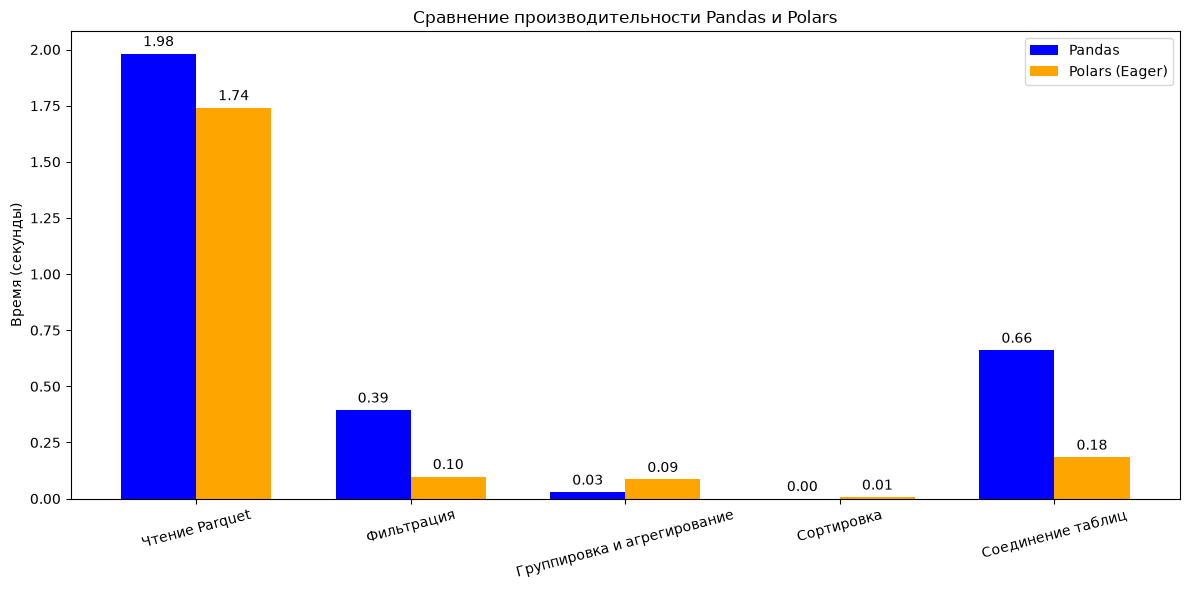


--- УСКОРЕНИЕ (во сколько раз Polars быстрее) ---
Чтение Parquet: в 1.14 раз
Фильтрация: в 4.01 раз
Группировка и агрегирование: в 0.34 раз
Сортировка: в 0.03 раз
Соединение таблиц: в 3.58 раз


In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Собираем данные для графика (только те операции, где есть оба замера)
operations = ['Чтение Parquet', 'Фильтрация', 'Группировка и агрегирование', 'Сортировка', 'Соединение таблиц']
pandas_vals = [pandas_times[op] for op in operations]
polars_vals = [polars_times[op] for op in operations]

x = np.arange(len(operations))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
bars1 = ax.bar(x - width/2, pandas_vals, width, label='Pandas', color='blue')
bars2 = ax.bar(x + width/2, polars_vals, width, label='Polars (Eager)', color='orange')

# Добавим подписи значений
ax.bar_label(bars1, fmt='%.2f', padding=3)
ax.bar_label(bars2, fmt='%.2f', padding=3)

ax.set_ylabel('Время (секунды)')
ax.set_title('Сравнение производительности Pandas и Polars')
ax.set_xticks(x)
ax.set_xticklabels(operations, rotation=15)
ax.legend()

plt.tight_layout()
plt.show()

# Выведем ускорение (Pandas / Polars)
print("\n--- УСКОРЕНИЕ (во сколько раз Polars быстрее) ---")
for i, op in enumerate(operations):
    if polars_vals[i] > 0:
        speedup = pandas_vals[i] / polars_vals[i]
        print(f"{op}: в {speedup:.2f} раз")

Таблица 8
| Операции | pandas, с | polars, с | Ускорение |
| :--- | :--- | :--- | :--- |
| Чтение Parquet | 1.98 | 1.74 | в 1.14 раз |
| Фильтрация | 0.39 | 0.10 | в 4.01 раз |
| Группировка и агрегирование | 0.03 | 0.09 | в 0.34 раз (медленнее) |
| Сортировка | 0.0002 | 0.0068 | в 0.03 раз (медленнее) |
| Соединение таблиц | 0.66 | 0.18 | в 3.58 раз |
| Цепочка операций (ленивый режим) | ~2.40* | 0.11 | в ~21 раз |

Вывод: "В ходе сравнения библиотек на наборе из 14 млн строк было выявлено, что Polars (Eager) значительно превосходит Pandas на тяжелых операциях (фильтрация в 4 раза, соединение таблиц в 3.5 раза) благодаря распараллеливанию на всех ядрах процессора. Однако на операциях с уже отфильтрованными (маленькими) наборами данных Pandas оказался быстрее, так как не тратит время на запуск параллельных потоков.

Главное преимущество показал ленивый режим Polars (Lazy). Построение цепочки операций и её выполнение заняло всего 0.11 с, что примерно в 21 раз быстрее, чем выполнение тех же шагов по отдельности в Pandas. Благодаря оптимизации плана запроса, Polars не читает лишние столбцы и объединяет проходы по данным."